# **Task 2 — DeiT**: does seeing more pixels help?

This week's seminar was about [DeiT](https://proceedings.mlr.press/v139/touvron21a.html): a ViT trained on ImageNet alone, with distillation, and fine-tuned at a higher resolution at the end. The paper reports that going from 224×224 to 384×384 images makes the model more accurate (Table 10). Today you check whether that holds for **our** model and **our** data.

This notebook loads the data and the model and gives you a **fixed evaluation**, so that every group measures its result the same way. Your own work starts after the baseline.

<details>
<summary>Reach out here if you have any problems</summary>
Taras Kutsyk — taras.kutsyk@doctoral.uj.edu.pl
</details>

# The task

**Question.** Does seeing more pixels help? Make the model run at 384×384, fine-tune it within the budget, and **answer the question for this model and this data, with evidence**. Then explain *why* you got the result you got, and what they teach you.

*Hint:* be wary of what you compare with, and of how your claim relates to the paper's.

**Fixed:**
- the starting model and the dataset;
- the `evaluate()` function below;
- the fine-tuning budget: **at most 100,000 training images per fine-tuned model** (about 11 passes over the training set);
- write the resizing of the position embeddings yourselves: no ready-made resizing (e.g. timm's `img_size=` argument or `resample_abs_pos_embed`).

Everything else is your choice.

**Bring to the lab:** your code + a short deck with your answer, the evidence for it, and your explanation. If your group defends this week, **every member should be able to explain any piece of the code**.

# Setup

**Step 0.** Runtime → Change runtime type → **T4 GPU**. Everything we need (PyTorch, torchvision, timm) is already installed on Colab.

**Step 1. Data.** [Imagewoof](https://github.com/fastai/imagenette): 10 dog breeds from ImageNet, 9,025 training and 3,929 validation photos, **at full size** (about 1.3 GB, under a minute to download).

In [1]:
import os, tarfile, time, urllib.request
import torch, timm
from torchvision import datasets

device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "Switch to a GPU runtime: Runtime -> Change runtime type -> T4 GPU"

URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2.tgz"
# we use the full-size image sets on purpose, not the smaller "-320" versions
# can you tell why? (in the deck)
if not os.path.exists("imagewoof2/val"):
    urllib.request.urlretrieve(URL, "imagewoof2.tgz")
    with tarfile.open("imagewoof2.tgz") as t:
        t.extractall(filter="data")
for split in ["train", "val"]:
    print(split, sum(len(f) for _, _, f in os.walk(f"imagewoof2/{split}")), "photos")

train 9025 photos
val 3929 photos


**Step 2. Model.** A distilled DeiT-S from the paper (12 blocks, 384 dims, 22M parameters, the DeiT-S⚗ of Table 5), trained on ImageNet at 224×224, together with the exact preprocessing it was trained with.

The model predicts one of 1000 ImageNet classes, so we map each Imagewoof folder (e.g. `n02086240` = Shih-Tzu) to its **ImageNet index**: the position of that breed among the model's 1000 outputs. You will need `to_imagenet` for your fine-tuning too.

<details>
<summary>Running the cell below can ask for your HF_TOKEN secret</summary>
Just press "Grant Access", it's automatically generated by Colab
</details>

In [2]:
model = timm.create_model("deit_small_distilled_patch16_224", pretrained=True).to(device).eval()
cfg = timm.data.resolve_data_config({}, model=model)  # the preprocessing the model was trained with

# ImageFolder labels the 10 folders 0..9, but the model outputs 1000 ImageNet classes:
# to_imagenet[label] translates a folder label into the ImageNet class index
wnids = list(timm.data.ImageNetInfo().label_names())
breeds = datasets.ImageFolder("imagewoof2/val").classes
to_imagenet = torch.tensor([wnids.index(w) for w in breeds], device=device)
print(cfg)
print("folder -> ImageNet index:", dict(zip(breeds, to_imagenet.tolist())))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 89.8MB            

model.safetensors: downloading bytes:           |  0.00B            

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.9, 'crop_mode': 'center'}
folder -> ImageNet index: {'n02086240': 155, 'n02087394': 159, 'n02088364': 162, 'n02089973': 167, 'n02093754': 182, 'n02096294': 193, 'n02099601': 207, 'n02105641': 229, 'n02111889': 258, 'n02115641': 273}


**Step 3. The fixed evaluation** (DON'T modify it). `evaluate(model, resolution)` resizes the validation photos for the given resolution exactly as the model's own preprocessing does, and returns the **top-1 accuracy over the 10 breeds**: the model's prediction is the highest-scoring of its 10 dog outputs.

In [3]:
@torch.no_grad()
def evaluate(model, resolution):
    """The fixed evaluation for task 2. Do not change it; report exactly what it prints.

    model      - any model that takes (batch, 3, resolution, resolution) images and returns 1000 logits
    resolution - the input size: 224 for the original model, e.g. 384 for yours
    returns: accuracy - top-1 over the 10 breeds, on the 3,929 Imagewoof validation photos
    """
    model.eval()
    tf = timm.data.create_transform(**dict(cfg, input_size=(3, resolution, resolution)))
    loader = torch.utils.data.DataLoader(datasets.ImageFolder("imagewoof2/val", transform=tf),
                                         batch_size=64, num_workers=2)
    correct = n = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
        correct += (logits[:, to_imagenet].argmax(-1) == y).sum().item()  # best of the 10 breeds
        n += len(y)
    return correct / n

**Step 4. Baseline.** Takes about half a minute. You should get **top-1 ≈ 97.20%** at 224. If not, something in the setup went wrong.

In [4]:
print(f"baseline DeiT-S distilled @224: top-1 {evaluate(model, 224):.2%}")

baseline DeiT-S distilled @224: top-1 97.20%


# Before you start

Think about **what exactly breaks in the model when you pass it higher-resolution images?** What's the simplest, most effective way to fix that?

Training photos are in `imagewoof2/train` (same folder structure as `val`).

# Your solution

Make the model run at 384, fine-tune within the budget, and collect the evidence for your answer. Good luck!

## Step 5. Settings

**First run:** keep `SMOKE_TEST = True`. Every fine-tuning then trains on only 640 images, so the whole notebook runs in a few minutes and you can check that nothing crashes. Smoke outputs go to `outputs_smoke/`, real ones to `outputs/`, so they never mix.

**Real runs:** set `SMOKE_TEST = False` and run this cell again.

What we write to the output folder:
- `results.json`, updated after each evaluation: every model's top-1, plus, for fine-tuned models, the per-epoch training log;
- `<run>.pt`, written once at the end of each fine-tuning run: the fine-tuned weights (about 90 MB each).

These files live on the Colab server and are deleted when it shuts down, so download the output folder when the runs are done.

In [13]:
# CELL 5.1 | settings, output folder, record()
import copy, json, math
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

SMOKE_TEST = False                          # True: quick check that everything runs. False: the real experiment.
BUDGET = 640 if SMOKE_TEST else 100_000    # training images per fine-tuned model (task limit: 100,000)
BATCH_SIZE = 32
LR = 2e-5                                  # CONSTANT LR. TODO: TUNE THE LR AND/OR ADD A SCHEDULE (E.G. WARMUP + COSINE) LATER

OUT_DIR = "outputs_smoke" if SMOKE_TEST else "outputs"     # results.json and the fine-tuned weights go here
RESULTS = os.path.join(OUT_DIR, "results.json")
os.makedirs(OUT_DIR, exist_ok=True)
print("outputs go to:", OUT_DIR)


def record(name, m, resolution, **info):
    """Runs the fixed evaluate() and adds the result to the results file (re-read every time, so runs from
    separate cells, or even separate sessions, all end up in one file)."""
    acc = evaluate(m, resolution)
    results = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}
    results[name] = dict(acc=acc, resolution=resolution, **info)
    with open(RESULTS, "w") as f:
        json.dump(results, f, indent=2)
    print(f">>> {name}: top-1 {acc:.2%}  (saved to {RESULTS})")

outputs go to: outputs


## Step 6. Make the model run at 384: 
## Interpolate the position embeddings. Logic is the same as on previous lecture. 

At 224 the image is a 14x14 grid of 16x16 patches (196 tokens, 198 with `[CLS]` and `[DIST]`), and `pos_embed` has exactly 198 learned vectors. At 384 the grid is 24×24 (576 + 2 = 578 tokens), so the table no longer fits.

The fix: treat the 196 patch vectors as a 14×14 "image" with 384 channels, resize it to 24×24 with bicubic interpolation, and leave `[CLS]` and `[DIST]` untouched (they have no position in the grid). All other weights don't depend on the number of tokens, so they work as they are.

In [6]:
# CELL 6.1 | resize_position_embeddings(), change_model_for_new_resolution()
def resize_position_embeddings(pos_embed, n_special_tokens, new_side):
    """
    n_special_tokens = 2 for CLS and DIST tokens.
    Resizes the position-embedding table: (1, n_special_tokens + old*old, dim) -> (1, n_special_tokens + new*new, dim).
    For our model at 384: (1, 198, 384) -> (1, 578, 384)."""

    special, patch_pos = pos_embed[:, :n_special_tokens], pos_embed[:, n_special_tokens:]  # (1, 2, 384), (1, 196, 384)
    old_side, dim = int(math.sqrt(patch_pos.shape[1])), patch_pos.shape[2]                 # 14, 384
    
    # Unflatten 196 positions into 14x14 
    patch_pos = patch_pos.reshape(1, old_side, old_side, dim)                # (1, 14, 14, 384)
    patch_pos = patch_pos.permute(0, 3, 1, 2)                                # (1, 384, 14, 14)
    
    # 3. Interpolate that "image" from 14x14 to 24x24. Patches are like pixels.
    patch_pos = F.interpolate(patch_pos, size=(new_side, new_side), mode="bicubic",
                                  align_corners=False)                           # (1, 384, 24, 24)
    
    # Permuta and flatten, so strart architecture is preserved.
    patch_pos = patch_pos.permute(0, 2, 3, 1)                                          # (1, 24, 24, 384)
    patch_pos = patch_pos.reshape(1, new_side * new_side, dim)                         # (1, 576, 384)

    # 5. Put CLS and DIST back in front, where the model expects them.
    return torch.cat([special, patch_pos], dim=1)                              # (1, 578, 384)


def change_model_for_new_resolution(base_model, resolution):
    """
    Returns a copy of model with new position embeddings."""
    model_copy = copy.deepcopy(base_model)                                            # independent copy: training it never touches `model`
    side = resolution // model_copy.patch_embed.patch_size[0]                         # patches per side: 384 // 16 = 24 (224 // 16 = 14)

    # Replace an old position embedding
    with torch.no_grad():
        model_copy.pos_embed = nn.Parameter(resize_position_embeddings(model_copy.pos_embed, model_copy.num_prefix_tokens, side))

    # Change other attributes that depend on old resolution.
    model_copy.patch_embed.img_size = (resolution, resolution)
    model_copy.patch_embed.grid_size = (side, side)
    model_copy.patch_embed.num_patches = side * side
    return model_copy

In [8]:
# CELL 6.2 | sanity checks (each line must pass silently); also creates m384, used in CELL 7.1
pe = model.pos_embed.detach().clone()
m384 = change_model_for_new_resolution(model, 384).eval()
assert torch.allclose(resize_position_embeddings(pe, 2, 14), pe), "14 -> 14 must change nothing"
assert m384.pos_embed.shape == (1, 2 + 24 * 24, 384), m384.pos_embed.shape
assert torch.equal(m384.pos_embed[:, :2], pe[:, :2]), "[CLS] and [DIST] must stay unchanged"
assert torch.equal(model.pos_embed, pe), "the original model must stay untouched"
with torch.no_grad():
    assert m384(torch.randn(2, 3, 384, 384, device=device)).shape == (2, 1000), "384 forward pass failed"
print("all checks passed:", tuple(pe.shape), "->", tuple(m384.pos_embed.shape))

all checks passed: (1, 198, 384) -> (1, 578, 384)


## Step 7. The two models without any training

- **`224_pretrain`**: the original model at 224 (the baseline again, now saved to the JSON).
- **`384_pretrain`**: the same pretrained weights at 384 with resized position embeddings, no training. Shows what the resizing alone does.

In [14]:
# CELL 7.1 | evaluate 224_pretrain and 384_pretrain (no training)
record("224_pretrain", model, 224, run=None, images_seen=0, train_minutes=0)
record("384_pretrain", m384, 384, run=None, images_seen=0, train_minutes=0)

>>> 224_pretrain: top-1 97.20%  (saved to outputs/results.json)
>>> 384_pretrain: top-1 96.69%  (saved to outputs/results.json)


## Step 8. Fine-tuning

One function used by all four runs, so 224 and 384 get exactly the same recipe and budget; resolution is the only difference. Every run starts from a **fresh copy of the pretrained model**. The loss is computed only over the 10 breed outputs (`to_imagenet`), the same 10 outputs `evaluate()` looks at.

`run` numbers the repeats (1, 2): each run number gives its own, repeatable shuffling and augmentation, so run 1 and run 2 differ, and a 224 and a 384 run with the same number see the photos in the same order.

To use saved weights later: `m = at_resolution(model, 384); m.load_state_dict(torch.load("outputs/384_fine-tune_run1.pt"))`.

In [10]:
# CELL 8.1 | train_transform(), finetune()
def train_transform(resolution):
    """A new random version of each photo every time it is loaded (evaluate() instead uses a fixed resize
    + centre crop). Without it every epoch would show the exact same images and the model could memorise them."""
    return transforms.Compose([
        # Pick a random rectangle covering 25-100%
        # cut it out and resize it to resolution x resolution with bicubic interpolation.
        transforms.RandomResizedCrop(resolution, scale=(0.25, 1.0),
                                     interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.RandomHorizontalFlip(),                                   # mirror left-right with probability 0.5
        transforms.ToTensor(),                                               # PIL image -> (3, H, W) floats in [0, 1]
        transforms.Normalize(cfg["mean"], cfg["std"]),                       # the normalization the model was trained with
    ])


def finetune(resolution, run):
    """Fine-tunes a fresh copy of the pretrained model at `resolution` on BUDGET training images."""
    torch.manual_seed(run)    # PyTorch's random generator: shuffling and random crops/flips come from it -> run 1 != run 2, each repeatable
    m = change_model_for_new_resolution(model, resolution).train()                             # fresh copy; at 224 the resize changes nothing
    train_set = datasets.ImageFolder("imagewoof2/train", transform=train_transform(resolution))
    loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                                         drop_last=True, num_workers=2)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.05)
    scaler = torch.amp.GradScaler()                                          # needed for float16 training
    total_steps = BUDGET // BATCH_SIZE                                       # 3125 steps x 32 = 100,000 images
    step, log, t0 = 0, [], time.time()

    while step < total_steps:                                                # one pass of this loop = one epoch
        losses, correct = [], 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = m(x)[:, to_imagenet]                                # (batch, 10): only the 10 breeds
            loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            losses.append(loss.item())
            correct += (logits.argmax(-1) == y).sum().item()
            step += 1
            if step == total_steps:                                          # budget reached in the middle of an epoch
                break
        log.append(dict(epoch=len(log) + 1, images_seen=step * BATCH_SIZE, train_loss=float(np.mean(losses)),
                        train_acc=correct / (len(losses) * BATCH_SIZE), minutes=round((time.time() - t0) / 60, 2)))
        e = log[-1]
        print(f"epoch {e['epoch']:>2} | images {e['images_seen']:>7,} | train loss {e['train_loss']:.3f} "
              f"| train acc {e['train_acc']:.1%} | {e['minutes']:.1f} min")

    assert step * BATCH_SIZE <= BUDGET, f"budget exceeded: {step * BATCH_SIZE} images"
    return m.eval(), dict(run=run, images_seen=step * BATCH_SIZE, train_minutes=log[-1]["minutes"], log=log)

### The four runs

Each cell is independent. Stats are saved at result.json, checkpoint at the end.

In [15]:
# CELL 8.2 | RUN 224_fine-tune, run 1: the fair control for 384_fine-tune
name = "224_fine-tune_run1"
m, info = finetune(resolution=224, run=1)
record(name, m, 224, **info)
torch.save(m.state_dict(), os.path.join(OUT_DIR, f"{name}.pt"))          # final weights, saved once
del m; torch.cuda.empty_cache()

epoch  1 | images   9,024 | train loss 0.112 | train acc 96.6% | 0.8 min
epoch  2 | images  18,048 | train loss 0.077 | train acc 97.6% | 1.7 min
epoch  3 | images  27,072 | train loss 0.061 | train acc 98.0% | 2.5 min
epoch  4 | images  36,096 | train loss 0.048 | train acc 98.5% | 3.3 min
epoch  5 | images  45,120 | train loss 0.033 | train acc 99.0% | 4.2 min
epoch  6 | images  54,144 | train loss 0.039 | train acc 98.9% | 5.0 min
epoch  7 | images  63,168 | train loss 0.033 | train acc 99.1% | 5.8 min
epoch  8 | images  72,192 | train loss 0.030 | train acc 99.1% | 6.6 min
epoch  9 | images  81,216 | train loss 0.031 | train acc 99.0% | 7.5 min
epoch 10 | images  90,240 | train loss 0.030 | train acc 99.1% | 8.3 min
epoch 11 | images  99,264 | train loss 0.022 | train acc 99.4% | 9.1 min
epoch 12 | images 100,000 | train loss 0.015 | train acc 99.6% | 9.2 min
>>> 224_fine-tune_run1: top-1 97.07%  (saved to outputs/results.json)


In [18]:
# CELL 8.3 | RUN 224_fine-tune, run 2: same, repeated
name = "224_fine-tune_run2"
m, info = finetune(resolution=224, run=2)
record(name, m, 224, **info)
torch.save(m.state_dict(), os.path.join(OUT_DIR, f"{name}.pt"))          # final weights, saved once
del m; torch.cuda.empty_cache()

epoch  1 | images   9,024 | train loss 0.106 | train acc 96.7% | 0.8 min
epoch  2 | images  18,048 | train loss 0.080 | train acc 97.5% | 1.6 min
epoch  3 | images  27,072 | train loss 0.058 | train acc 98.3% | 2.5 min
epoch  4 | images  36,096 | train loss 0.047 | train acc 98.4% | 3.3 min
epoch  5 | images  45,120 | train loss 0.042 | train acc 98.7% | 4.1 min
epoch  6 | images  54,144 | train loss 0.042 | train acc 98.8% | 4.9 min
epoch  7 | images  63,168 | train loss 0.032 | train acc 99.0% | 5.8 min
epoch  8 | images  72,192 | train loss 0.033 | train acc 99.1% | 6.6 min
epoch  9 | images  81,216 | train loss 0.029 | train acc 99.1% | 7.4 min
epoch 10 | images  90,240 | train loss 0.030 | train acc 99.1% | 8.2 min
epoch 11 | images  99,264 | train loss 0.027 | train acc 99.2% | 9.0 min
epoch 12 | images 100,000 | train loss 0.021 | train acc 99.3% | 9.1 min
>>> 224_fine-tune_run2: top-1 96.77%  (saved to outputs/results.json)


In [16]:
# CELL 8.4 | RUN 384_fine-tune, run 1: the model the question is about
name = "384_fine-tune_run1"
m, info = finetune(resolution=384, run=1)
record(name, m, 384, **info)
torch.save(m.state_dict(), os.path.join(OUT_DIR, f"{name}.pt"))          # final weights, saved once
del m; torch.cuda.empty_cache()

epoch  1 | images   9,024 | train loss 0.114 | train acc 96.5% | 1.8 min
epoch  2 | images  18,048 | train loss 0.077 | train acc 97.7% | 3.6 min
epoch  3 | images  27,072 | train loss 0.057 | train acc 98.0% | 5.4 min
epoch  4 | images  36,096 | train loss 0.048 | train acc 98.6% | 7.2 min
epoch  5 | images  45,120 | train loss 0.033 | train acc 99.0% | 9.0 min
epoch  6 | images  54,144 | train loss 0.034 | train acc 98.9% | 10.8 min
epoch  7 | images  63,168 | train loss 0.034 | train acc 99.0% | 12.6 min
epoch  8 | images  72,192 | train loss 0.031 | train acc 99.0% | 14.4 min
epoch  9 | images  81,216 | train loss 0.028 | train acc 99.1% | 16.2 min
epoch 10 | images  90,240 | train loss 0.025 | train acc 99.4% | 18.1 min
epoch 11 | images  99,264 | train loss 0.021 | train acc 99.4% | 19.9 min
epoch 12 | images 100,000 | train loss 0.011 | train acc 99.7% | 20.0 min
>>> 384_fine-tune_run1: top-1 97.25%  (saved to outputs/results.json)


In [17]:
# CELL 8.5 | RUN 384_fine-tune, run 2: same, repeated
name = "384_fine-tune_run2"
m, info = finetune(resolution=384, run=2)
record(name, m, 384, **info)
torch.save(m.state_dict(), os.path.join(OUT_DIR, f"{name}.pt"))          # final weights, saved once
del m; torch.cuda.empty_cache()

epoch  1 | images   9,024 | train loss 0.110 | train acc 96.5% | 1.8 min
epoch  2 | images  18,048 | train loss 0.080 | train acc 97.6% | 3.6 min
epoch  3 | images  27,072 | train loss 0.057 | train acc 98.3% | 5.5 min
epoch  4 | images  36,096 | train loss 0.044 | train acc 98.5% | 7.3 min
epoch  5 | images  45,120 | train loss 0.039 | train acc 98.7% | 9.1 min
epoch  6 | images  54,144 | train loss 0.039 | train acc 98.9% | 10.9 min
epoch  7 | images  63,168 | train loss 0.030 | train acc 99.0% | 12.7 min
epoch  8 | images  72,192 | train loss 0.035 | train acc 99.0% | 14.6 min
epoch  9 | images  81,216 | train loss 0.024 | train acc 99.3% | 16.3 min
epoch 10 | images  90,240 | train loss 0.028 | train acc 99.1% | 18.2 min
epoch 11 | images  99,264 | train loss 0.027 | train acc 99.3% | 20.0 min
epoch 12 | images 100,000 | train loss 0.015 | train acc 99.3% | 20.1 min
>>> 384_fine-tune_run2: top-1 96.82%  (saved to outputs/results.json)


## Step 9. Summary

Reads the results file, so it works after a restart and with only some runs finished.

- **384_fine-tune − 224_fine-tune** is the answer: same fine-tuning, only the resolution differs.
- **224_fine-tune − 224_pretrain** is what fine-tuning alone does.
- **384_fine-tune − 224_pretrain** is the naive comparison: it mixes the two effects.
- **384_pretrain − 224_pretrain** is what the resizing alone does, without training.

In [20]:
# CELL 9.1 | summary table
R = json.load(open(RESULTS))
print(f"{'model':<22}{'top-1':>8}{'train min':>11}")
for name, r in R.items():
    print(f"{name:<22}{r['acc']:>8.2%}{r['train_minutes']:>11}")


def pts(a, b):  # accuracy of model a minus model b, in percentage points
    return f"{100 * (R[a]['acc'] - R[b]['acc']):+.2f} pts" if a in R and b in R else "(run missing)"


print("\n384_pretrain - 224_pretrain      resizing only, no training:", pts("384_pretrain", "224_pretrain"))
for run in (1, 2):
    print(f"run {run}:")
    print("  384_fine-tune - 224_fine-tune  more pixels, same fine-tuning (THE ANSWER):",
          pts(f"384_fine-tune_run{run}", f"224_fine-tune_run{run}"))
    print("  224_fine-tune - 224_pretrain   fine-tuning only:                          ",
          pts(f"224_fine-tune_run{run}", "224_pretrain"))
    print("  384_fine-tune - 224_pretrain   naive comparison (mixes both effects):     ",
          pts(f"384_fine-tune_run{run}", "224_pretrain"))

print(f"\nfor scale: 1 validation photo = {100 / 3929:.3f} pts; "
      f"standard error of one accuracy at ~97% = {100 * math.sqrt(0.97 * 0.03 / 3929):.2f} pts")

model                    top-1  train min
224_pretrain            97.20%          0
384_pretrain            96.69%          0
224_fine-tune_run1      97.07%       9.21
224_fine-tune_run2      96.77%       9.08
384_fine-tune_run1      97.25%       20.0
384_fine-tune_run2      96.82%      20.15

384_pretrain - 224_pretrain      resizing only, no training: -0.51 pts
run 1:
  384_fine-tune - 224_fine-tune  more pixels, same fine-tuning (THE ANSWER): +0.18 pts
  224_fine-tune - 224_pretrain   fine-tuning only:                           -0.13 pts
  384_fine-tune - 224_pretrain   naive comparison (mixes both effects):      +0.05 pts
run 2:
  384_fine-tune - 224_fine-tune  more pixels, same fine-tuning (THE ANSWER): +0.05 pts
  224_fine-tune - 224_pretrain   fine-tuning only:                           -0.43 pts
  384_fine-tune - 224_pretrain   naive comparison (mixes both effects):      -0.38 pts

for scale: 1 validation photo = 0.025 pts; standard error of one accuracy at ~97% = 0.27 pts


## Step 10. Charts for the deck


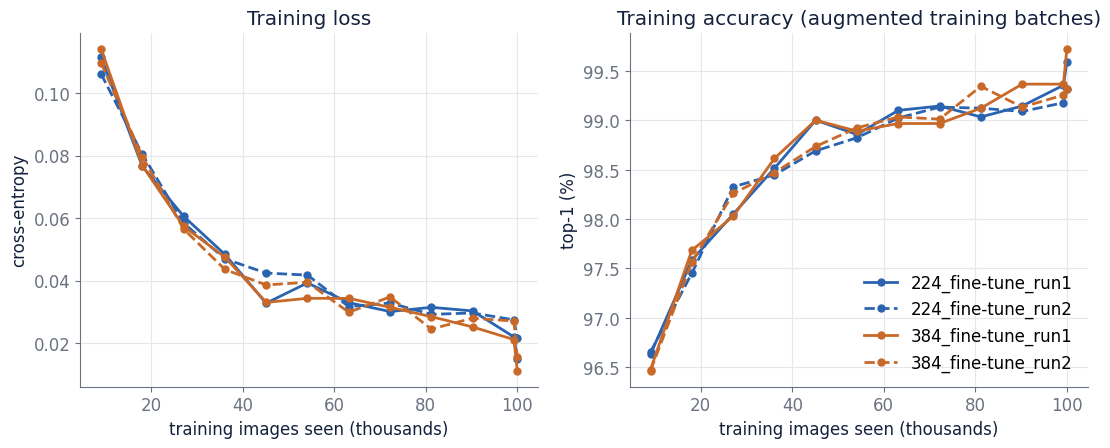

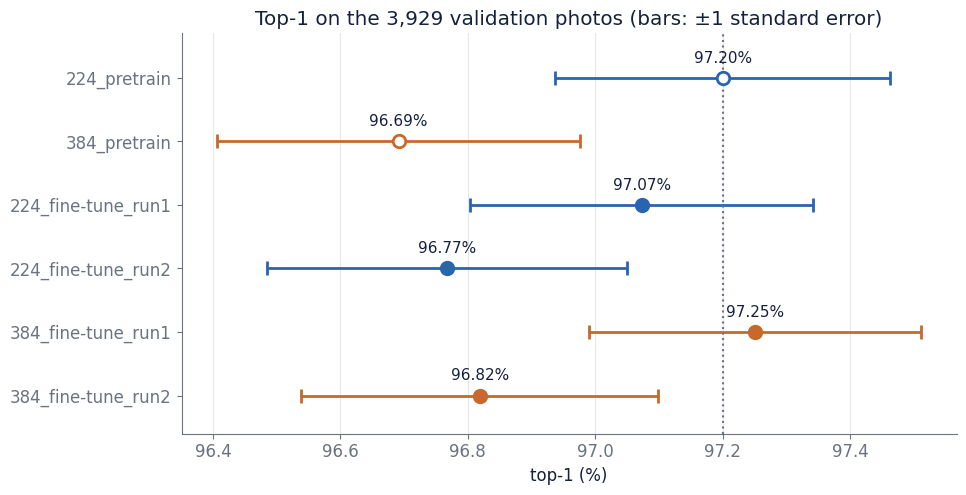

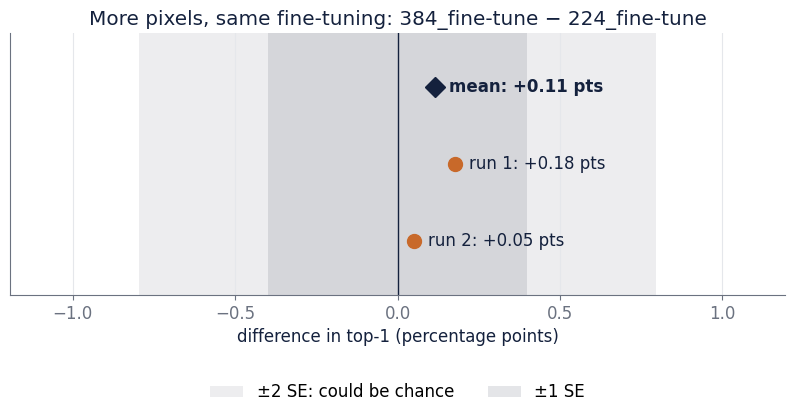

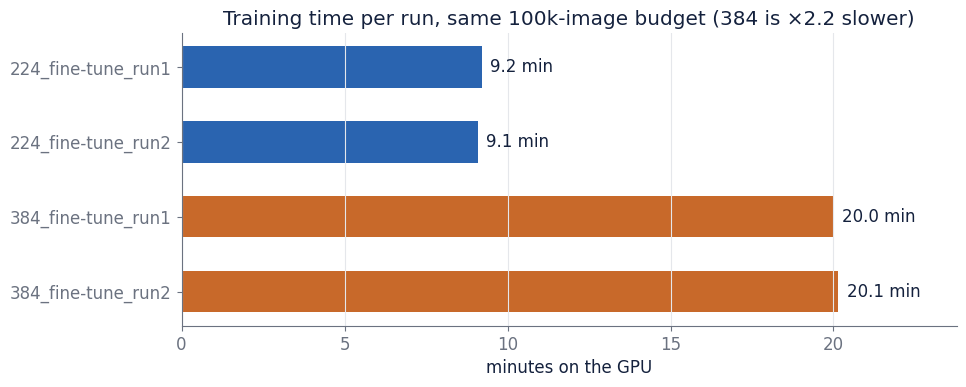

saved:
  outputs/training_curves.png
  outputs/accuracy.png
  outputs/answer.png
  outputs/training_time.png


['outputs/training_curves.png',
 'outputs/accuracy.png',
 'outputs/answer.png',
 'outputs/training_time.png']

In [21]:
# CELL 10.1 | plot_results(): the charts for the deck, drawn from results.json
import matplotlib.pyplot as plt

COLORS = {224: "#2A64B0", 384: "#C8692A"}     # 224 = blue, 384 = orange (colour-blind safe pair)
LINESTYLES = {1: "-", 2: "--"}                # run 1 solid, run 2 dashed: identity never rests on colour alone
INK, MUTED, GRID = "#14213D", "#6B7280", "#E5E7EB"
ORDER = ["224_pretrain", "384_pretrain", "224_fine-tune_run1", "224_fine-tune_run2",
         "384_fine-tune_run1", "384_fine-tune_run2"]
N_VAL = 3929                                  # validation photos used by evaluate()


def se_pts(acc):
    """Standard error of one accuracy measured on N_VAL photos, in percentage points."""
    return 100 * math.sqrt(acc * (1 - acc) / N_VAL)


def plot_results(results_path=None, out_dir=None):
    """Draws 4 charts from results.json and saves each one as a PNG next to it:
    training_curves.png, accuracy.png, answer.png, training_time.png. Runs not finished yet are skipped."""
    results_path = results_path or RESULTS
    out_dir = out_dir or OUT_DIR
    R = json.load(open(results_path))
    finetuned = [n for n in ORDER if n in R and R[n].get("log")]
    plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
                         "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                         "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False})
    saved = []

    def save(fig, filename):
        path = os.path.join(out_dir, filename)
        fig.savefig(path, dpi=200, bbox_inches="tight")
        plt.show()
        saved.append(path)

    # 1. Training curves: loss and accuracy on the (augmented) training batches, one point per epoch.
    if finetuned:
        fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.6))
        for name in finetuned:
            r = R[name]
            x = [e["images_seen"] / 1000 for e in r["log"]]
            style = dict(color=COLORS[r["resolution"]], ls=LINESTYLES.get(r["run"], ":"), lw=2,
                         marker="o", ms=5, label=name)
            ax_loss.plot(x, [e["train_loss"] for e in r["log"]], **style)
            ax_acc.plot(x, [100 * e["train_acc"] for e in r["log"]], **style)
        ax_loss.set(title="Training loss", xlabel="training images seen (thousands)", ylabel="cross-entropy")
        ax_acc.set(title="Training accuracy (augmented training batches)",
                   xlabel="training images seen (thousands)", ylabel="top-1 (%)")
        ax_acc.legend(loc="lower right")
        save(fig, "training_curves.png")

    # 2. Final top-1 of every model, with +-1 standard error. Hollow dots: no training; filled: fine-tuned.
    names = [n for n in ORDER if n in R]
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(names) + 1.6))
    for i, name in enumerate(names):
        r, acc = R[name], 100 * R[name]["acc"]
        color = COLORS[r["resolution"]]
        ax.errorbar(acc, i, xerr=se_pts(r["acc"]), fmt="o", ms=9, lw=2, capsize=5, color=color,
                    mfc=color if r.get("log") else "white", mew=2)
        ax.annotate(f"{acc:.2f}%", (acc, i), xytext=(0, 11), textcoords="offset points",
                    ha="center", color=INK, fontsize=11)
    if "224_pretrain" in R:
        ax.axvline(100 * R["224_pretrain"]["acc"], color=MUTED, ls=":", lw=1.5)
    ax.set_yticks(range(len(names)), names)
    ax.set_ylim(len(names) - 0.4, -0.7)                                     # first model on top
    ax.grid(axis="y", visible=False)
    ax.set(title="Top-1 on the 3,929 validation photos (bars: ±1 standard error)", xlabel="top-1 (%)")
    save(fig, "accuracy.png")

    # 3. The answer: 384_fine-tune minus 224_fine-tune, per run, against the band chance alone could produce.
    pairs = [(run, f"384_fine-tune_run{run}", f"224_fine-tune_run{run}") for run in (1, 2)]
    pairs = [(run, a, b) for run, a, b in pairs if a in R and b in R]
    if pairs:
        diffs = [100 * (R[a]["acc"] - R[b]["acc"]) for _, a, b in pairs]
        se_diff = max(math.sqrt(se_pts(R[a]["acc"]) ** 2 + se_pts(R[b]["acc"]) ** 2) for _, a, b in pairs)
        fig, ax = plt.subplots(figsize=(10, 3.4))
        ax.axvspan(-2 * se_diff, 2 * se_diff, color=MUTED, alpha=0.12, lw=0, label="±2 SE: could be chance")
        ax.axvspan(-se_diff, se_diff, color=MUTED, alpha=0.18, lw=0, label="±1 SE")
        ax.axvline(0, color=INK, lw=1)
        for y, ((run, _, _), d) in enumerate(zip(pairs, diffs), start=1):
            ax.plot(d, y, "o", color=COLORS[384], ms=10)
            ax.annotate(f"run {run}: {d:+.2f} pts", (d, y), xytext=(10, 0), textcoords="offset points",
                        va="center", color=INK)
        mean = float(np.mean(diffs))
        ax.plot(mean, 0, "D", color=INK, ms=10)
        ax.annotate(f"mean: {mean:+.2f} pts", (mean, 0), xytext=(10, 0), textcoords="offset points",
                    va="center", color=INK, fontweight="bold")
        reach = max(3 * se_diff, max(abs(d) for d in diffs) + 1.2 * se_diff)
        ax.set_xlim(-reach, reach)
        ax.set_yticks([])
        ax.set_ylim(len(pairs) + 0.7, -0.7)
        ax.grid(axis="y", visible=False)
        ax.set(title="More pixels, same fine-tuning: 384_fine-tune − 224_fine-tune",
               xlabel="difference in top-1 (percentage points)")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)  # below the plot, clear of the labels
        save(fig, "answer.png")

    # 4. Cost: training minutes per fine-tuned run.
    if finetuned:
        fig, ax = plt.subplots(figsize=(10, 0.6 * len(finetuned) + 1.4))
        minutes = [R[n]["train_minutes"] for n in finetuned]
        ax.barh(range(len(finetuned)), minutes, height=0.55,
                color=[COLORS[R[n]["resolution"]] for n in finetuned])
        for i, m in enumerate(minutes):
            ax.annotate(f"{m:.1f} min", (m, i), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
        ax.set_yticks(range(len(finetuned)), finetuned)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        ax.set_xlim(0, max(minutes) * 1.18)
        t224 = [R[n]["train_minutes"] for n in finetuned if R[n]["resolution"] == 224]
        t384 = [R[n]["train_minutes"] for n in finetuned if R[n]["resolution"] == 384]
        ratio = f" (384 is ×{np.mean(t384) / np.mean(t224):.1f} slower)" if t224 and t384 else ""
        ax.set(title=f"Training time per run, same 100k-image budget{ratio}", xlabel="minutes on the GPU")
        save(fig, "training_time.png")

    print("saved:", *saved, sep="\n  ")
    return saved


plot_results()